# Acquire external datasets

Four attached Kaggle Datasets → the same 512 px preprocessing used for EyeQ → one
manifest. Output becomes `retina-external-512`.

| Dataset | Slug | Images | Role |
|---|---|---|---|
| DRIMDB | `subhajournal/drimdb-diabetic-retinopathy-images-database` | 194 | External test |
| IDRiD | `mohamedabdalkader/indian-diabetic-retinopathy-image-dataset-idrid` | 516 | Pathology control |
| DeepDRiD | `nancyhisham/deepdrid` | 1,600 | External test + real defect labels |
| **FQS** | *you upload it — see section 0* | **2,246** | **External test, three-class + MOS** |
| | | **4,556** | |

> **Shared helpers are in cell 3.** Single copy of `crop_fov`, `pad_square`,
> `preprocess` and `stem`, byte-identical to your EyeQ notebook and
> `src/data/preprocess.py`. If they drift, external images get different treatment from
> EyeQ images and the Week 11 generalisation study measures your preprocessing rather
> than domain shift. Nothing errors. You would not find out.

## 0 · Getting FQS into Kaggle

You have `FIQSDataset.zip` locally — 9.07 GiB. **Do not upload all of it.**

### What is inside

```
FIQSDataset.zip                        9.74 GB unpacked
├── divisions/          30 files       683 KB    ← labels live here
│   └── cross_validation-{00..09}-{train,val,test}.xlsx
├── full_size_images/   2,246 PNG      7.42 GB   1942 × 1942, 3.3 MB each
└── images/             2,246 PNG      2.32 GB   1024 × 1024, 1.0 MB each
```

### Upload `images/` and `divisions/` only — about 2.3 GB

Skipping `full_size_images/` cuts the upload by **3.2×**.

**Why 1024 rather than 1942.** You resize to 512 regardless, so the question is whether
the authors' 1942 → 1024 step damages the blur signal you are trying to detect. Three
reasons it does not matter much:

- 1942 → 1024 is only a 1.9× downsample. Even a naive filter is fairly benign at that
  ratio.
- Whatever artefact it introduces is applied to **every** image, so it is systematic
  rather than correlated with the label.
- Your other datasets already span wildly different downsample ratios — EyePACS ~6×,
  IDRiD ~8×, DeepDRiD ~3.5×, DRIMDB ~1.3×. FQS at 2× sits in the middle of variation
  you already have.

Record the double resize in the crosswalk as a caveat and move on. If you later suspect
it matters, the full-size copy is still on your machine.

### Steps

1. Extract `FIQSDataset.zip` locally
2. Make a folder containing **only** `images/` and `divisions/`
3. [kaggle.com/datasets](https://www.kaggle.com/datasets) → **New Dataset** → drag that
   folder in
4. Title `fqs-fundus-quality-scores`, visibility **Private**, **Create**
5. Wait for processing, then **Add Data** in this notebook

**If the browser upload stalls**, use the Kaggle API instead — it chunks and resumes:

```bash
pip install kaggle
# put kaggle.json in ~/.kaggle/ (Account → Settings → Create New Token)
kaggle datasets init -p /path/to/fqs-folder
# edit the generated dataset-metadata.json, then:
kaggle datasets create -p /path/to/fqs-folder --dir-mode zip
```

### What FQS gives you that nothing else does

**It is your only external three-class test set.** DRIMDB and DeepDRiD are both binary,
so neither can measure the Good↔Usable boundary — which is exactly where your model is
weakest (classical baseline: Usable F1 0.502, recall 0.450).

It also ships **continuous MOS scores 0–100**, so you can report rank correlation
alongside classification accuracy.

**Its class balance is inverted from EyeQ**, deliberately — the authors wanted more
Reject images to cover more degradation types:

| | Good | Usable | Reject |
|---|---|---|---|
| FQS | 516 (23%) | 793 (35%) | **937 (42%)** |
| EyeQ test | 52% | 28% | 20% |

A model trained on 66% Good will over-predict Good here. Expect that in the confusion
matrix; it is prior mismatch, not failure.

**The authors state the semantic gap for you.** In their own external validation on
EyeQ they report a higher error rate in the Usable category, attributed to *differences
in quality assessment criteria between the two datasets*. Quote that in the crosswalk —
you are citing a documented gap rather than asserting one.

**Citation:** Gong, Zheng, Zhuo Deng, Run Gan, et al. 2025. "Acquire Continuous and
Precise Score for Fundus Image Quality Assessment: FTHNet and FQS Dataset."
*Scientific Reports* 15: 40524.

## 1 · Attach all four

**Add Data** → search the slug → **Add**. Inputs mount read-only and do not count
against your 20 GB working quota.

Notes on the three Kaggle mirrors, all verified against published counts:

**DRIMDB** — `Good` 125 / `Bad` 69 / `Outlier` 22 = 216, matching Sevik et al. Outliers
are not fundus images and get dropped, leaving **194**. The upload also nests iWeb
gallery exports (thumbnails at 100 × 75) inside each class folder — the loader excludes
them **by folder depth, not by size**, because some of those derivatives are full
resolution.

*Caveat:* DRIMDB is easy. Published classifiers exceed 98% because good and bad are
grossly obvious at 760 × 570. A high score proves less than it looks.

**IDRiD** — the upload merges two sources: 516 at IDRiD's native 4288 × 2848, and 1,032
at 4880 × 3862 with a different aspect ratio and unknown provenance. Train and Test each
renumber from 0001, so 309 filenames collide across them. The loader filters by native
resolution and prefixes ids with the split name.

**DeepDRiD** — folder structure matches the official GitHub repo and it ships the
original `LICENSE` and `README`. `regular_fundus_images` only; ultra-widefield is a
different imaging modality. Also ships `regular-fundus-source-*.csv` with no quality
column, which a CSV glob would silently fold into the join.

In [1]:
# =====================================================================
# SHARED HELPERS - identical copy in every notebook and in
# src/data/preprocess.py. Do not edit one without the others.
# =====================================================================
import os

import cv2
import numpy as np

TARGET = 512


def stem(s):
    return os.path.splitext(os.path.basename(str(s)))[0]


def crop_fov(img, tol=7):
    """Trim the black surround around the circular field of view."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    mask = gray > tol
    if not mask.any():
        return img
    ys, xs = np.where(mask)
    return img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]


def pad_square(img):
    """Pad the short side so resizing does not distort the retina."""
    h, w = img.shape[:2]
    s = max(h, w)
    t, l = (s - h) // 2, (s - w) // 2
    return cv2.copyMakeBorder(img, t, s - h - t, l, s - w - l,
                              cv2.BORDER_CONSTANT, value=[0, 0, 0])


def preprocess(img, size=TARGET):
    """Full pipeline: crop, pad, resize. BGR in, BGR out."""
    return cv2.resize(pad_square(crop_fov(img)), (size, size),
                      interpolation=cv2.INTER_AREA)


print("helpers defined")

helpers defined


In [2]:
import re
import shutil
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm



INPUT = Path("/kaggle/input/datasets")
WORK = Path("/kaggle/working")
OUT = WORK / "external_512"
OUT.mkdir(exist_ok=True)

IMG_EXTS = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}

GOOD, USABLE, REJECT = 0, 1, 2
SCHEMA = ["dataset", "image_id", "src_path", "patient_id",
          "quality_raw", "quality", "role", "dr_grade", "mos",
          "clarity", "field_def", "artifact"]


def resolve(slug, root=INPUT, max_depth=3):
    """Find an attached dataset by slug, whatever the mount layout.

    Kaggle mounts competitions and datasets under different prefixes, so
    search rather than assume. Depth-limited - never recurses into the data.
    """
    for depth in range(1, max_depth + 1):
        hits = [p for p in root.glob("/".join(["*"] * (depth - 1) + [slug]))
                if p.is_dir()]
        if hits:
            return hits[0]
    return None


DRIMDB = resolve("drimdb-diabetic-retinopathy-images-database")
IDRID = resolve("indian-diabetic-retinopathy-image-dataset-idrid")
DEEPDRID = resolve("deepdrid")
FQS = resolve("fqs-fundus-quality-scores")      # <-- your upload's slug

for n, p in [("DRIMDB", DRIMDB), ("IDRiD", IDRID),
             ("DeepDRiD", DEEPDRID), ("FQS", FQS)]:
    print(f"{n:10s} {'OK     ' if p else 'MISSING'} {p}")

DRIMDB     OK      /kaggle/input/datasets/subhajournal/drimdb-diabetic-retinopathy-images-database
IDRiD      OK      /kaggle/input/datasets/mohamedabdalkader/indian-diabetic-retinopathy-image-dataset-idrid
DeepDRiD   OK      /kaggle/input/datasets/nancyhisham/deepdrid
FQS        OK      /kaggle/input/datasets/izuchukwuoruche/fqs-fundus-quality-scores


## 2 · Verify against published ground truth

A data card says what someone *claims* they uploaded. This checks what is there.

Two things matter: **count** matching the published figure, and images at **native
resolution**. A mirror resized to 224 square would be unusable — you are detecting blur,
and the resizing already destroyed it.

In [3]:
EXPECTED = {
    "drimdb":   (216,  "Good 125 + Bad 69 + Outlier 22 (Sevik et al.)"),
    "idrid":    (516,  "516 at native 4288x2848 (Porwal et al. 2018)"),
    "deepdrid": (2256, "2000 regular + 256 ultra-widefield (Liu et al. 2022)"),
    "fqs":      (2246, "2246 at 1024x1024 (Gong et al. 2025)"),
}


def verify(name, root, sample=25):
    print(f"\n{'=' * 66}\n{name}")
    if not root or not Path(root).exists():
        print("  NOT ATTACHED")
        return

    paths = [p for p in Path(root).rglob("*") if p.suffix.lower() in IMG_EXTS]
    exp, note = EXPECTED[name]
    print(f"  expected {exp:,}   found {len(paths):,}   ({note})")

    step = max(1, len(paths) // sample)
    dims = []
    for p in paths[::step][:sample]:
        try:
            with Image.open(p) as im:      # header only, no decode
                dims.append(im.size)
        except Exception:
            pass
    if dims:
        print(f"  sizes: {Counter(dims).most_common(3)}")
        uniq = Counter(dims)
        if len(uniq) == 1:
            (w, h), _ = uniq.most_common(1)[0]
            if w == h and w <= 512:
                print(f"  *** RESIZED to {w}x{h} - unusable for blur detection ***")


for n, r in [("drimdb", DRIMDB), ("idrid", IDRID),
             ("deepdrid", DEEPDRID), ("fqs", FQS)]:
    verify(n, r)


drimdb
  expected 216   found 651   (Good 125 + Bad 69 + Outlier 22 (Sevik et al.))
  sizes: [((760, 570), 16), ((100, 75), 9)]

idrid
  expected 516   found 1,548   (516 at native 4288x2848 (Porwal et al. 2018))
  sizes: [((4880, 3862), 20), ((4288, 2848), 5)]

deepdrid
  expected 2,256   found 2,256   (2000 regular + 256 ultra-widefield (Liu et al. 2022))
  sizes: [((1976, 1984), 13), ((1736, 1824), 9), ((3900, 3072), 2)]

fqs
  expected 2,246   found 2,246   (2246 at 1024x1024 (Gong et al. 2025))
  sizes: [((1024, 1024), 25)]


**Reading it.** DRIMDB reports more than 216 because of the nested gallery exports —
the loader handles that. IDRiD reports ~1,548 across two resolutions; the loader filters
to the 516 native ones. DeepDRiD should hit 2,256 exactly. **FQS should hit 2,246
exactly at a uniform 1024 × 1024** — that uniformity is expected here, since the authors
standardised the size, and it is above the 512 threshold so no warning fires.

## 3 · Find the label columns

You know the image layout. What you need is the **column names** in each label file —
they differ between sources and are not worth guessing.

In [4]:
def tree(root, max_depth=3, max_files=4):
    root = Path(root)
    for dirpath, dirnames, filenames in os.walk(root):
        parts = Path(dirpath).relative_to(root).parts
        if len(parts) > max_depth:
            dirnames.clear()
            continue
        ind = "   " * len(parts)
        print(f"{ind}{Path(dirpath).name or root.name}/  ({len(filenames)} files)")
        for f in sorted(filenames)[:max_files]:
            print(f"{ind}   {f}")
        if len(filenames) > max_files:
            print(f"{ind}   ... +{len(filenames) - max_files} more")


def find_tables(root, n=4):
    """Locate and preview every CSV / Excel file under root."""
    for dirpath, _, filenames in os.walk(root):
        for f in sorted(filenames):
            if not f.lower().endswith((".csv", ".xlsx", ".xls")):
                continue
            p = Path(dirpath) / f
            print(f"\n{'=' * 70}\n{p}")
            try:
                df = (pd.read_csv(p) if f.lower().endswith(".csv")
                      else pd.read_excel(p))
                print(f"shape={df.shape}  columns={list(df.columns)}")
                print(df.head(n).to_string(max_colwidth=26))
                for c in df.columns:
                    if df[c].dtype == object or df[c].nunique() <= 10:
                        print(f"  {c}: {df[c].value_counts().head(6).to_dict()}")
            except Exception as e:
                print(f"  could not read: {e}")

In [5]:
# FQS: labels live in divisions/. The ten folds are different random splits
# of the SAME 2,246 images, so fold 00's train+val+test = every image once
# (1797 + 112 + 337 = 2246). FQS is test-only for us, so folds are irrelevant.
tree(FQS, max_depth=2)
print()
find_tables(FQS / "divisions")

fqs-fundus-quality-scores/  (0 files)
   images/  (2246 files)
      00000.PNG
      00001.PNG
      00002.PNG
      00003.PNG
      ... +2242 more
   divisions/  (30 files)
      cross_validation-00-test.xlsx
      cross_validation-00-train.xlsx
      cross_validation-00-val.xlsx
      cross_validation-01-test.xlsx
      ... +26 more


/kaggle/input/datasets/izuchukwuoruche/fqs-fundus-quality-scores/divisions/cross_validation-00-test.xlsx
shape=(449, 4)  columns=['Unnamed: 0', 'file_name', 'qualityLevel', 'meanOpinionScore']
   Unnamed: 0   file_name  qualityLevel  meanOpinionScore
0         238  01625.jpeg             2         63.000000
1         247  00290.jpeg             0         79.666667
2         250  02554.jpeg             1         76.666667
3         253  02157.jpeg             2         15.666667
  file_name: {'01952.jpeg': 1, '02524.jpeg': 1, '02553.jpeg': 1, '00270.jpeg': 1, '00877.jpeg': 1, '01906.jpeg': 1}
  qualityLevel: {2: 190, 1: 172, 0: 87}

/kaggle/input/dataset

In [6]:
tree(DEEPDRID, max_depth=3)
find_tables(DEEPDRID / "regular_fundus_images")

deepdrid/  (2 files)
   LICENSE
   README.md
   regular_fundus_images/  (0 files)
      regular-fundus-training/  (4 files)
         .~Readme.docx
         Readme.docx
         regular-fundus-source-training.csv
         regular-fundus-training.csv
         Images/  (0 files)
      Online-Challenge1&2-Evaluation/  (6 files)
         .~Readme.docx
         Challenge1_labels.xlsx
         Challenge1_upload.csv
         Challenge2_labels.xlsx
         ... +2 more
         Images/  (0 files)
      regular-fundus-validation/  (4 files)
         .~Readme.docx
         Readme.docx
         regular-fundus-source-validation.csv
         regular-fundus-validation.csv
         Images/  (0 files)
   ultra-widefield_images/  (0 files)
      ultra-widefield-validation/  (2 files)
         Readme.txt
         ultra-widefield-validation.csv
         Images/  (0 files)
      ultra-widefield-training/  (2 files)
         Readme.txt
         ultra-widefield-training.csv
         Images/  (0 files)
      

In [7]:
tree(IDRID, max_depth=3)
find_tables(IDRID)

indian-diabetic-retinopathy-image-dataset-idrid/  (0 files)
   IDRiD/  (0 files)
      Test/  (1 files)
         annotations.csv
         images/  (309 files)
            IDRiD_0001.jpg
            IDRiD_0002.jpg
            IDRiD_0003.jpg
            IDRiD_0004.jpg
            ... +305 more
      Train/  (1 files)
         annotations.csv
         images/  (1239 files)
            IDRiD_0001.jpg
            IDRiD_0002.jpg
            IDRiD_0003.jpg
            IDRiD_0004.jpg
            ... +1235 more

/kaggle/input/datasets/mohamedabdalkader/indian-diabetic-retinopathy-image-dataset-idrid/IDRiD/Test/annotations.csv
shape=(309, 5)  columns=['Image name', 'Retinopathy grade', 'Risk of macular edema', 'class', 'caption']
       Image name  Retinopathy grade  Risk of macular edema                      class                    caption
0  IDRiD_0001.jpg                  0                      0                      No_DR  A fundus photograph of...
1  IDRiD_0002.jpg                  0      

## 4 · Loaders

Each returns the same columns, so everything downstream is source-agnostic.

- `quality_raw` — exactly as the source gives it. Never overwrite.
- `quality` — harmonised 0/1/2 via the crosswalk.
- `role` — `external` for generalisation tests, `control` for IDRiD.
- `mos`, `clarity`, `field_def`, `artifact`, `dr_grade` — extra signal where a source
  provides it, null elsewhere.

In [8]:
# ---------------------------------------------------------------------
# CROSSWALK - keep in sync with docs/crosswalk.md
#
# DRIMDB   Good -> 0, Bad -> 2, Outlier dropped. Binary source: the Usable
#          middle class cannot be recovered, so DRIMDB is excluded from
#          3-class evaluation and reported on a collapsed binary task.
#
# DeepDRiD Binary overall quality. Direction verified against the sub-scores
#          rather than assumed: quality 1 has higher clarity (8.66 vs 7.11)
#          and 3.2x fewer artifacts (1.27 vs 4.11). So 1 = good.
#
# IDRiD    All high quality -> 0. Control only, never scored for generalisation.
#
# FQS      Three-level, same schema as EyeQ. Thresholds from the paper:
#          Good 80-100, Usable 60-79, Reject 0-59 on the MOS scale.
#          The ONLY external source that can test the Good/Usable boundary.
# ---------------------------------------------------------------------

DRIMDB_MAP = {"good": GOOD, "bad": REJECT}       # outlier deliberately absent
DEEPDRID_MAP = {1: GOOD, 0: REJECT}
FQS_MAP = {"good": GOOD, "usable": USABLE, "reject": REJECT}

IDRID_NATIVE = (4288, 2848)
NULLS = {"dr_grade": None, "mos": None,
         "clarity": None, "field_def": None, "artifact": None}


def _check(df, name):
    missing = set(SCHEMA) - set(df.columns)
    if missing:
        raise ValueError(f"{name} missing columns: {missing}")
    if df.quality.isna().any():
        raise ValueError(f"{name}: {df.quality.isna().sum()} unmapped quality")
    if df.image_id.duplicated().any():
        raise ValueError(f"{name}: {df.image_id.duplicated().sum()} duplicate ids")
    return df[SCHEMA].reset_index(drop=True)

In [9]:
def load_drimdb(root=DRIMDB):
    """Good 125 + Bad 69 = 194.

    Only images whose IMMEDIATE parent is the class folder. The upload nests
    iWeb gallery exports under <class>/drimdb_<class>/iwebalbumfiles/.
    Excluded by depth, not size - some of those are full resolution.
    """
    rows = []
    for cls, q in DRIMDB_MAP.items():
        folder = next((d for d in Path(root).rglob("*")
                       if d.is_dir() and d.name.lower() == cls), None)
        if folder is None:
            print(f"  WARNING: no '{cls}' folder")
            continue
        for f in sorted(folder.iterdir()):        # iterdir, NOT rglob
            if f.suffix.lower() not in IMG_EXTS:
                continue
            sid = re.sub(r"[^A-Za-z0-9]+", "_", stem(f)).strip("_")
            sid = sid[7:] if sid.lower().startswith("drimdb_") else sid
            rows.append({"dataset": "drimdb", "image_id": f"drimdb_{sid}",
                         "src_path": str(f), "patient_id": f"drimdb_{sid}",
                         "quality_raw": cls, "quality": q,
                         "role": "external", **NULLS})

    df = pd.DataFrame(rows)
    print(f"drimdb   : {len(df):4d}  {df.quality_raw.value_counts().to_dict()}")
    assert len(df) == 194, f"expected 194, got {len(df)}"
    return _check(df, "drimdb")


raw_dr = load_drimdb()
raw_dr.head()

drimdb   :  194  {'good': 125, 'bad': 69}


,dataset,image_id,src_path,patient_id,quality_raw,quality,role,dr_grade,mos,clarity,field_def,artifact
0,drimdb,drimdb_good_1,/kaggle/input/datasets/subhajournal/drimdb-dia...,drimdb_good_1,good,0,external,None,None,None,None,None
1,drimdb,drimdb_good_10,/kaggle/input/datasets/subhajournal/drimdb-dia...,drimdb_good_10,good,0,external,None,None,None,None,None
2,drimdb,drimdb_good_100,/kaggle/input/datasets/subhajournal/drimdb-dia...,drimdb_good_100,good,0,external,None,None,None,None,None
3,drimdb,drimdb_good_101,/kaggle/input/datasets/subhajournal/drimdb-dia...,drimdb_good_101,good,0,external,None,None,None,None,None
4,drimdb,drimdb_good_102,/kaggle/input/datasets/subhajournal/drimdb-dia...,drimdb_good_102,good,0,external,None,None,None,None,None


In [10]:
def load_idrid(root=IDRID, native=IDRID_NATIVE):
    """Genuine IDRiD only, identified by native resolution.

    The upload merges two sources and renumbers each split from 0001:
        516 at 4288x2848  <- IDRiD native, matches the published count
       1032 at 4880x3862  <- different aspect ratio, not IDRiD
    Train/IDRiD_0001.jpg and Test/IDRiD_0001.jpg are DIFFERENT images, so
    image_id carries the split prefix.

    dr_grade is kept because the Week 10 pathology control asks whether
    high-grade images get flagged ungradable.
    """
    rows = []
    for csv in sorted(Path(root).rglob("annotations.csv")):
        split = csv.parent.name.lower()           # Train / Test
        img_dir = csv.parent / "images"
        ann = pd.read_csv(csv).set_index("Image name")
        kept = skipped = 0

        for p in sorted(img_dir.iterdir()):
            if p.suffix.lower() not in IMG_EXTS:
                continue
            with Image.open(p) as im:
                if im.size != native:
                    skipped += 1
                    continue
            rows.append({"dataset": "idrid",
                         "image_id": f"idrid_{split}_{stem(p)}",
                         "src_path": str(p),
                         "patient_id": f"idrid_{split}_{stem(p)}",
                         "quality_raw": "high", "quality": GOOD,
                         "role": "control",       # never a generalisation test
                         **{**NULLS,
                            "dr_grade": ann["Retinopathy grade"].get(p.name)}})
            kept += 1

        print(f"  {split:6s}: kept {kept:4d}, skipped {skipped:4d}")

    df = pd.DataFrame(rows)
    print(f"idrid    : {len(df):4d} at native resolution")
    print(f"           grades {df.dr_grade.value_counts().sort_index().to_dict()}")
    assert len(df) == 516, f"expected 516, got {len(df)}"
    return _check(df, "idrid")


raw_id = load_idrid()
raw_id.head()

  test  : kept  103, skipped  206
  train : kept  413, skipped  826
idrid    :  516 at native resolution
           grades {0: 168, 1: 25, 2: 168, 3: 93, 4: 62}


,dataset,image_id,src_path,patient_id,quality_raw,quality,role,dr_grade,mos,clarity,field_def,artifact
0,idrid,idrid_test_IDRiD_0006,/kaggle/input/datasets/mohamedabdalkader/india...,idrid_test_IDRiD_0006,high,0,control,2,None,None,None,None
1,idrid,idrid_test_IDRiD_0011,/kaggle/input/datasets/mohamedabdalkader/india...,idrid_test_IDRiD_0011,high,0,control,3,None,None,None,None
2,idrid,idrid_test_IDRiD_0013,/kaggle/input/datasets/mohamedabdalkader/india...,idrid_test_IDRiD_0013,high,0,control,2,None,None,None,None
3,idrid,idrid_test_IDRiD_0016,/kaggle/input/datasets/mohamedabdalkader/india...,idrid_test_IDRiD_0016,high,0,control,3,None,None,None,None
4,idrid,idrid_test_IDRiD_0017,/kaggle/input/datasets/mohamedabdalkader/india...,idrid_test_IDRiD_0017,high,0,control,0,None,None,None,None


### DeepDRiD — set the three column names from the cell 8 output

Name the label CSVs explicitly. `regular-fundus-source-*.csv` also exist and carry no
quality column, so a glob silently poisons the join.

Keep Clarity / Field definition / Artifact — they are your only real defect labels,
used in Week 9 to validate the synthetic degradation pipeline.

In [11]:
def load_deepdrid(root=DEEPDRID):
    """Regular fundus only. Ultra-widefield is a different modality."""
    reg = Path(root) / "regular_fundus_images"
    want = {"regular-fundus-training.csv", "regular-fundus-validation.csv"}
    csvs = sorted(p for p in reg.rglob("*.csv") if p.name.lower() in want)
    print("label files:", [p.name for p in csvs])

    lab = pd.concat([pd.read_csv(p) for p in csvs], ignore_index=True)
    print(f"{len(lab)} labelled rows")
    print("Overall quality:", lab["Overall quality"].value_counts().to_dict())

    index = {stem(p): str(p) for p in reg.rglob("*")
             if p.suffix.lower() in IMG_EXTS}
    lab["stem"] = lab["image_id"].map(stem)
    lab["src_path"] = lab["stem"].map(index)
    miss = lab.src_path.isna().sum()
    if miss:
        print(f"WARNING: {miss} labelled images not on disk")
    lab = lab.dropna(subset=["src_path", "Overall quality"]).drop_duplicates("stem")

    df = pd.DataFrame({
        "dataset": "deepdrid",
        "image_id": "deepdrid_" + lab["stem"],
        "src_path": lab["src_path"],
        "patient_id": "deepdrid_" + lab["patient_id"].astype(str),
        "quality_raw": lab["Overall quality"].astype(int),
        "quality": lab["Overall quality"].astype(int).map(DEEPDRID_MAP),
        "role": "external",
        "dr_grade": lab["patient_DR_Level"],
        "mos": None,
        "clarity": lab["Clarity"],
        "field_def": lab["Field definition"],
        "artifact": lab["Artifact"],
    })

    print(f"deepdrid : {len(df):4d}  {df.quality_raw.value_counts().to_dict()}")
    print(f"           {df.patient_id.nunique()} patients "
          f"({len(df) / df.patient_id.nunique():.1f} images each)")
    return _check(df, "deepdrid")


raw_dd = load_deepdrid()
raw_dd.head()

label files: ['regular-fundus-training.csv', 'regular-fundus-validation.csv']
1600 labelled rows
Overall quality: {0: 842, 1: 758}
deepdrid : 1600  {0: 842, 1: 758}
           400 patients (4.0 images each)


,dataset,image_id,src_path,patient_id,quality_raw,quality,role,dr_grade,mos,clarity,field_def,artifact
0,deepdrid,deepdrid_1_l1,/kaggle/input/datasets/nancyhisham/deepdrid/re...,deepdrid_1,0,2,external,0,None,8,8,4
1,deepdrid,deepdrid_1_l2,/kaggle/input/datasets/nancyhisham/deepdrid/re...,deepdrid_1,0,2,external,0,None,8,8,0
2,deepdrid,deepdrid_1_r1,/kaggle/input/datasets/nancyhisham/deepdrid/re...,deepdrid_1,0,2,external,0,None,8,8,4
3,deepdrid,deepdrid_1_r2,/kaggle/input/datasets/nancyhisham/deepdrid/re...,deepdrid_1,0,2,external,0,None,10,8,0
4,deepdrid,deepdrid_2_l1,/kaggle/input/datasets/nancyhisham/deepdrid/re...,deepdrid_2,0,2,external,2,None,10,8,6


### FQS — column names confirmed, no editing needed

Cell 10 settled three things I had assumed wrongly:

**Fold sizes are 1572 / 225 / 449, not 1797 / 112 / 337.** The released splits are
70/10/20, not the 80/5/15 the paper describes. Irrelevant here — what matters is that
they still sum to exactly 2,246, so fold 00 covers every image once.

**Filenames disagree between the label file and the disk.** The xlsx says
`01625.jpeg`; the images are `00000.PNG`. `stem()` strips the extension from both sides,
so the join works — but a raw filename match would have silently found nothing.

**`qualityLevel` is numeric and already matches our encoding.** Class totals across
fold 00 come to 514 Good / 794 Usable / 938 Reject against the paper's 516 / 793 / 937 —
within one or two images, so the ordering is unambiguous: **0 = Good, 1 = Usable,
2 = Reject, identical to EyeQ.** No remapping required.

The MOS values agree: label 0 samples score 79.7–84.0, label 1 score 61.8–76.7, label 2
score 15.7–63.0. Cell 22 verifies this properly across all 2,246.

In [12]:
def load_fqs(root=FQS, fold="00"):
    """2,246 images, three-level labels + continuous MOS 0-100.

    Our only external source that can test the Good/Usable boundary - DRIMDB
    and DeepDRiD are both binary, and that boundary is where the model is
    weakest (classical baseline: Usable F1 0.502).

    Fold 00's train + val + test = 1572 + 225 + 449 = 2246, every image once.
    The other nine folds are alternative random splits of the same images;
    irrelevant here, since FQS is test-only for us.

    Images are already border-cropped and square (1024x1024), so crop_fov
    finds nothing to trim and pad_square is a no-op. Same function, less work.
    """
    div = Path(root) / "divisions"
    parts = []
    for split in ("train", "val", "test"):
        f = div / f"cross_validation-{fold}-{split}.xlsx"
        parts.append(pd.read_excel(f))
        print(f"  {f.name}: {len(parts[-1])} rows")

    lab = pd.concat(parts, ignore_index=True)
    print(f"columns: {list(lab.columns)}")

    # confirmed from the divisions/*.xlsx preview. 'Unnamed: 0' is a pandas
    # index artefact from however the authors saved these - ignored.
    ID_COL = "file_name"              # e.g. '01625.jpeg'
    LABEL_COL = "qualityLevel"        # numeric 0/1/2, same encoding as EyeQ
    MOS_COL = "meanOpinionScore"      # continuous 0-100

    # The label file says .jpeg; the images on disk are .PNG. stem() strips
    # the extension from both sides, so the join works. A raw filename match
    # would find nothing and fail silently.
    index = {stem(p): str(p) for p in (Path(root) / "images").iterdir()
             if p.suffix.lower() in IMG_EXTS}
    print(f"{len(index)} images on disk")

    lab["stem"] = lab[ID_COL].map(stem)
    lab["src_path"] = lab["stem"].map(index)
    miss = lab.src_path.isna().sum()
    if miss:
        print(f"WARNING: {miss} labelled images not on disk")
        print("  unmatched examples:", lab[lab.src_path.isna()][ID_COL].head().tolist())
    lab = lab.dropna(subset=["src_path"]).drop_duplicates("stem")

    # qualityLevel is already 0=Good / 1=Usable / 2=Reject. Handle a string
    # variant defensively in case another fold file differs.
    rawlab = lab[LABEL_COL]
    mapped = (rawlab.str.strip().str.lower().map(FQS_MAP)
              if rawlab.dtype == object else rawlab.astype(int))

    df = pd.DataFrame({
        "dataset": "fqs",
        "image_id": "fqs_" + lab["stem"],
        "src_path": lab["src_path"],
        "patient_id": "fqs_" + lab["stem"],   # EXIF stripped, no patient ids
        "quality_raw": rawlab,
        "quality": mapped,
        "role": "external",
        "dr_grade": None,
        "mos": lab[MOS_COL],
        "clarity": None, "field_def": None, "artifact": None,
    })

    counts = df.quality.value_counts().sort_index().to_dict()
    print(f"fqs      : {len(df):4d}  {counts}")
    print(f"           expect {{0: 514, 1: 794, 2: 938}}")
    print(f"           (paper Fig 2c says 516 / 793 / 937 - the released "
          f"splits differ by 1-2 images)")
    print(f"           MOS range {df.mos.min():.1f} - {df.mos.max():.1f}")
    assert len(df) == 2246, f"expected 2246, got {len(df)}"
    return _check(df, "fqs")


raw_fq = load_fqs()
raw_fq.head()

  cross_validation-00-train.xlsx: 1572 rows
  cross_validation-00-val.xlsx: 225 rows
  cross_validation-00-test.xlsx: 449 rows
columns: ['Unnamed: 0', 'file_name', 'qualityLevel', 'meanOpinionScore']
2246 images on disk
fqs      : 2246  {0: 514, 1: 794, 2: 938}
           expect {0: 514, 1: 794, 2: 938}
           (paper Fig 2c says 516 / 793 / 937 - the released splits differ by 1-2 images)
           MOS range 1.0 - 95.3


,dataset,image_id,src_path,patient_id,quality_raw,quality,role,dr_grade,mos,clarity,field_def,artifact
0,fqs,fqs_00232,/kaggle/input/datasets/izuchukwuoruche/fqs-fun...,fqs_00232,2,2,external,None,54.333333,None,None,None
1,fqs,fqs_00357,/kaggle/input/datasets/izuchukwuoruche/fqs-fun...,fqs_00357,0,0,external,None,80.833333,None,None,None
2,fqs,fqs_00347,/kaggle/input/datasets/izuchukwuoruche/fqs-fun...,fqs_00347,2,2,external,None,52.500000,None,None,None
3,fqs,fqs_08920,/kaggle/input/datasets/izuchukwuoruche/fqs-fun...,fqs_08920,1,1,external,None,73.666667,None,None,None
4,fqs,fqs_00311,/kaggle/input/datasets/izuchukwuoruche/fqs-fun...,fqs_00311,1,1,external,None,69.833333,None,None,None


**Two checks on the FQS output.**

**Class counts should read `{0: 514, 1: 794, 2: 938}`.** If they come out permuted the
mapping is wrong — but given the numeric column already matches EyeQ's encoding, they
should not.

**MOS must rise Reject → Usable → Good.** Run the next cell; it decides objectively
rather than by eye.

> A handful of boundary cases will not match the paper's stated thresholds (Good 80–100,
> Usable 60–79, Reject 0–59) — one sampled image carries label 2 with a MOS of 63, and
> another label 0 with 79.7. That is expected from their labelling procedure: broad
> categories were assigned first, then scores refined by ±2 in a third pass. The class
> *means* are what the check tests.

In [13]:
# Does MOS agree with the three-level label?
chk = raw_fq.dropna(subset=["mos"]).copy()
chk["mos"] = pd.to_numeric(chk["mos"], errors="coerce")

print("mean MOS by mapped class (paper: Reject 0-59, Usable 60-79, Good 80-100)")
print(chk.groupby("quality")["mos"].agg(["mean", "min", "max", "count"]).round(1))

means = chk.groupby("quality")["mos"].mean()
if means.get(GOOD, 0) > means.get(USABLE, 0) > means.get(REJECT, 0):
    print("\nCONSISTENT - mapping is the right way round")
else:
    print("\nINCONSISTENT - MOS does not rise Reject -> Usable -> Good.")
    print("Flip FQS_MAP and re-run.")

mean MOS by mapped class (paper: Reject 0-59, Usable 60-79, Good 80-100)
         mean   min   max  count
quality                         
0        82.0  66.0  95.3    514
1        69.1  38.3  85.8    794
2        40.9   1.0  69.7    938

CONSISTENT - mapping is the right way round


In [14]:
raw = pd.concat([raw_dr, raw_id, raw_dd, raw_fq], ignore_index=True)

print(f"total {len(raw)} images\n")
print(raw.groupby(["dataset", "role", "quality"]).size().unstack(fill_value=0))
print()
print("three-class capable (Usable present):",
      sorted(raw[raw.quality == USABLE].dataset.unique()))

total 4556 images

quality              0    1    2
dataset  role                   
deepdrid external  758    0  842
drimdb   external  125    0   69
fqs      external  514  794  938
idrid    control   516    0    0

three-class capable (Usable present): ['fqs']


/tmp/ipykernel_16/539283479.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  raw = pd.concat([raw_dr, raw_id, raw_dd, raw_fq], ignore_index=True)


## 5 · Preprocess

Identical pipeline to EyeQ — the helpers from cell 3, unchanged.

**Do not special-case any dataset here.** The moment you do, the Week 11 generalisation
study measures preprocessing differences instead of domain shift.

~4,556 images at 512 px is roughly 1.1 GB. Comfortable against the 20 GB quota.

In [15]:
def convert(row, out_dir=OUT, size=TARGET):
    fname = f"{row.image_id}.png"
    dest = out_dir / fname
    if dest.exists():
        return fname
    img = cv2.imread(row.src_path)
    if img is None:
        return None
    cv2.imwrite(str(dest), preprocess(img, size))
    return fname


results, failed = [], []
for row in tqdm(raw.itertuples(), total=len(raw)):
    try:
        f = convert(row)
        if f is None:
            raise ValueError("decode failed")
        results.append(f)
    except Exception as e:
        results.append(None)
        failed.append((row.dataset, row.image_id, str(e)))

raw["filename"] = results
print(f"\nwritten {sum(r is not None for r in results)}   failed {len(failed)}")
if failed:
    pd.DataFrame(failed, columns=["dataset", "image_id", "error"]).to_csv(
        WORK / "external_failed.csv", index=False)
    print(pd.DataFrame(failed, columns=["dataset", "image_id", "error"]).head())

  0%|          | 0/4556 [00:00<?, ?it/s]


written 4556   failed 0


## 6 · Manifest

In [16]:
manifest = raw.dropna(subset=["filename"])[
    ["dataset", "image_id", "filename", "patient_id", "quality_raw", "quality",
     "role", "dr_grade", "mos", "clarity", "field_def", "artifact",
     "src_path"]].copy()

manifest.to_csv(WORK / "manifest_external_512.csv", index=False)

print(manifest.shape)
print(manifest.groupby(["dataset", "role"]).size())
print()
print(pd.crosstab(manifest.dataset, manifest.quality))
manifest.head()

(4556, 13)
dataset   role    
deepdrid  external    1600
drimdb    external     194
fqs       external    2246
idrid     control      516
dtype: int64

quality     0    1    2
dataset                
deepdrid  758    0  842
drimdb    125    0   69
fqs       514  794  938
idrid     516    0    0


,dataset,image_id,filename,patient_id,quality_raw,quality,role,dr_grade,mos,clarity,field_def,artifact,src_path
0,drimdb,drimdb_good_1,drimdb_good_1.png,drimdb_good_1,good,0,external,None,NaN,None,None,None,/kaggle/input/datasets/subhajournal/drimdb-dia...
1,drimdb,drimdb_good_10,drimdb_good_10.png,drimdb_good_10,good,0,external,None,NaN,None,None,None,/kaggle/input/datasets/subhajournal/drimdb-dia...
2,drimdb,drimdb_good_100,drimdb_good_100.png,drimdb_good_100,good,0,external,None,NaN,None,None,None,/kaggle/input/datasets/subhajournal/drimdb-dia...
3,drimdb,drimdb_good_101,drimdb_good_101.png,drimdb_good_101,good,0,external,None,NaN,None,None,None,/kaggle/input/datasets/subhajournal/drimdb-dia...
4,drimdb,drimdb_good_102,drimdb_good_102.png,drimdb_good_102,good,0,external,None,NaN,None,None,None,/kaggle/input/datasets/subhajournal/drimdb-dia...


`src_path` points at `/kaggle/input` and will not resolve for anyone attaching the
published Dataset. Kept for provenance only — always load via `filename`.

## 7 · Check the output before publishing

Both checks take a minute and both catch errors that stay invisible until Week 11.

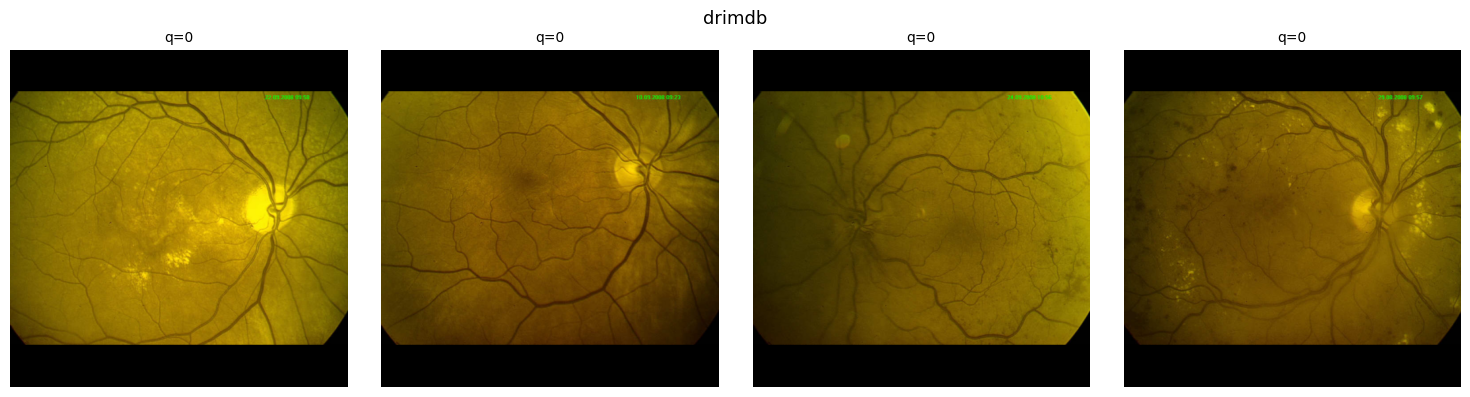

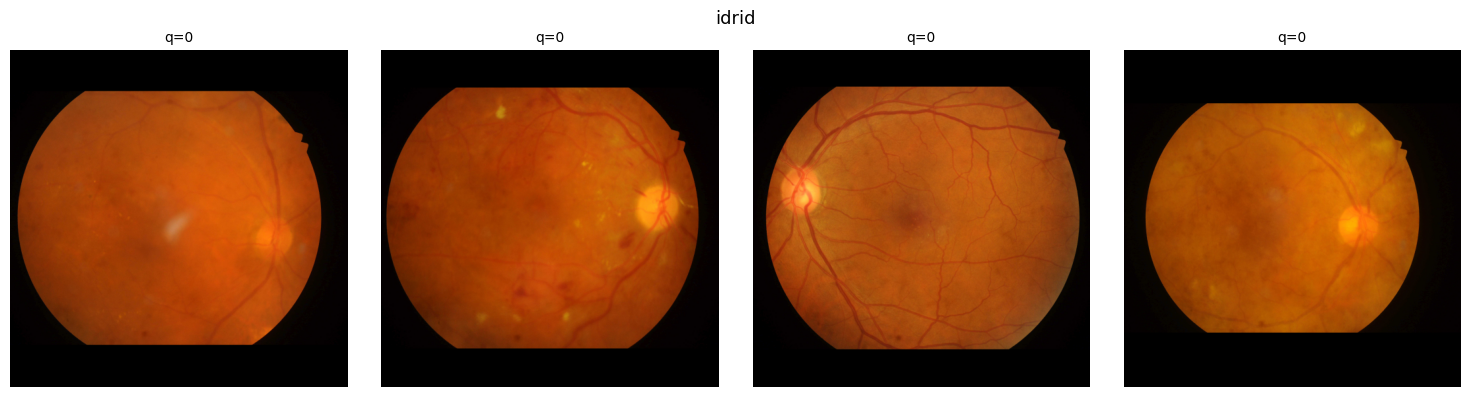

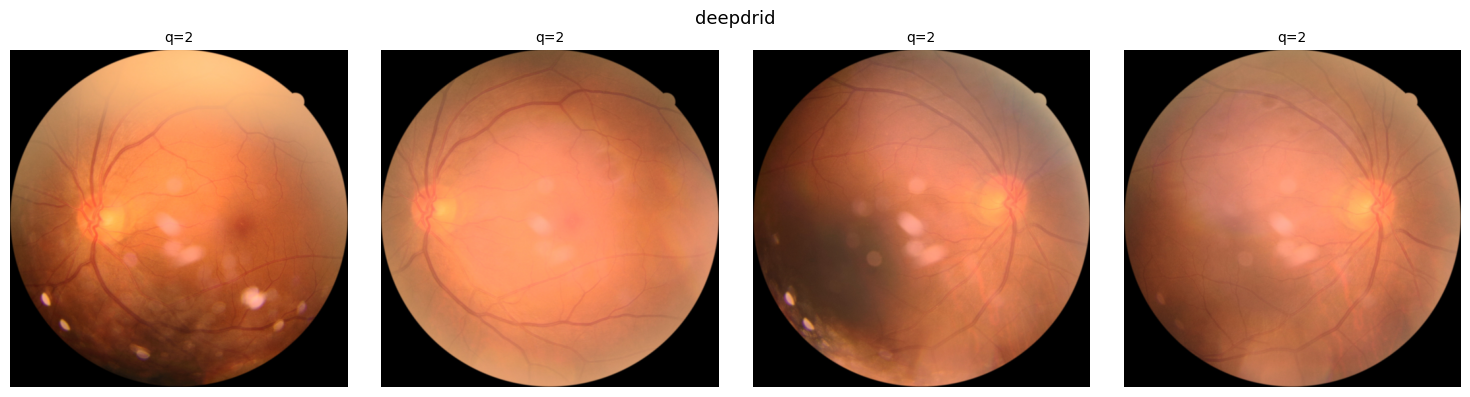

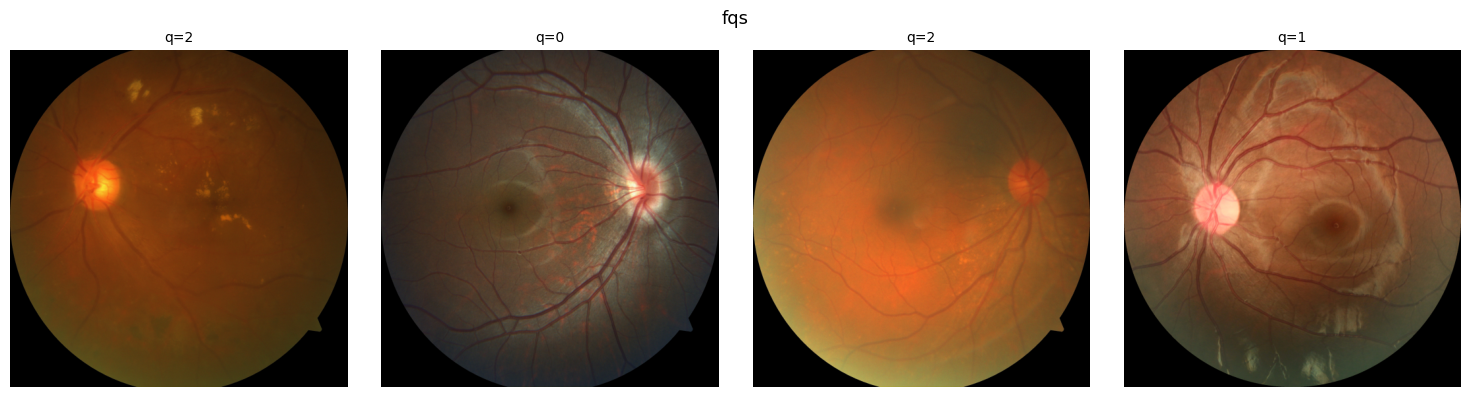

In [17]:
# --- 1: did preprocessing work on each source? ---
for ds in manifest.dataset.unique():
    sub = manifest[manifest.dataset == ds].head(4)
    fig, axes = plt.subplots(1, 4, figsize=(15, 4))
    for ax in axes:
        ax.axis("off")
    for ax, (_, r) in zip(axes, sub.iterrows()):
        img = cv2.imread(str(OUT / r.filename))
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(f"q={r.quality}", fontsize=10)
    plt.suptitle(ds, fontsize=13)
    plt.tight_layout()
    plt.show()

Look for: retina fills the frame, thin black wedges only, nothing clipped at the
edges.

If one source comes out badly cropped its black level differs — raise `tol` in
`crop_fov` *while exploring*, then decide whether to document the difference as a
limitation rather than special-casing the pipeline.

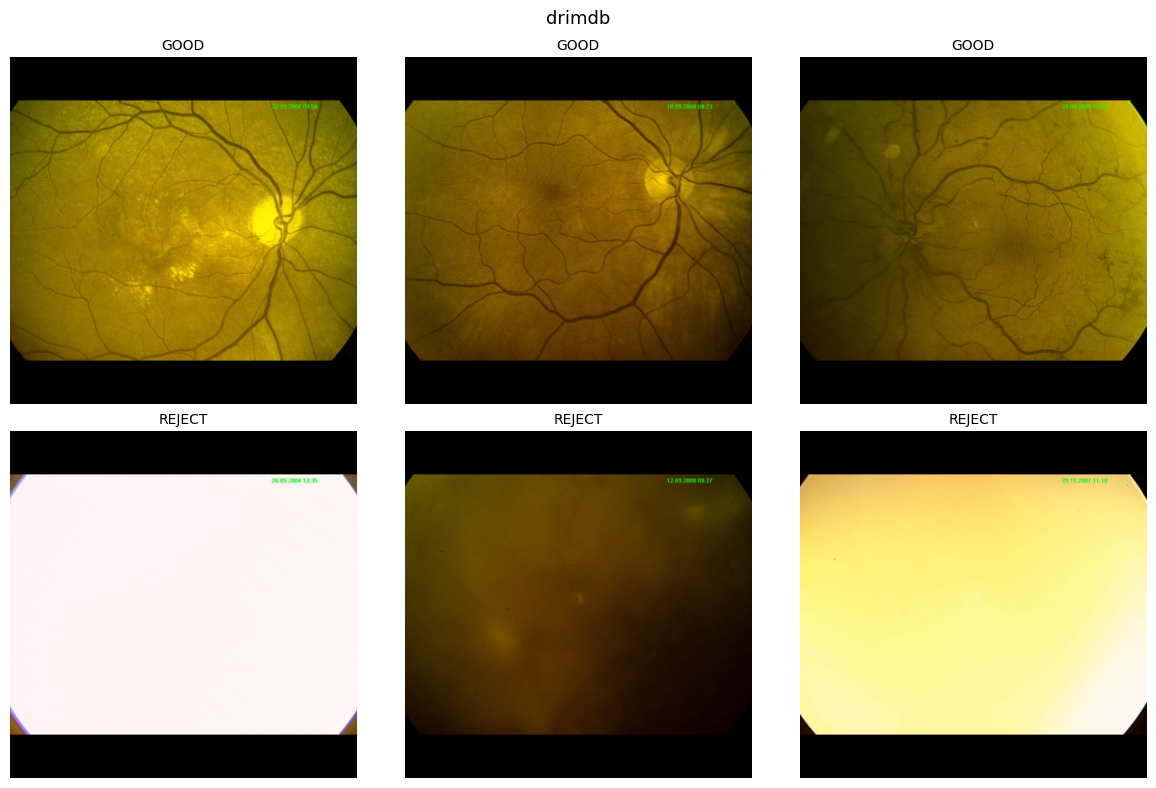

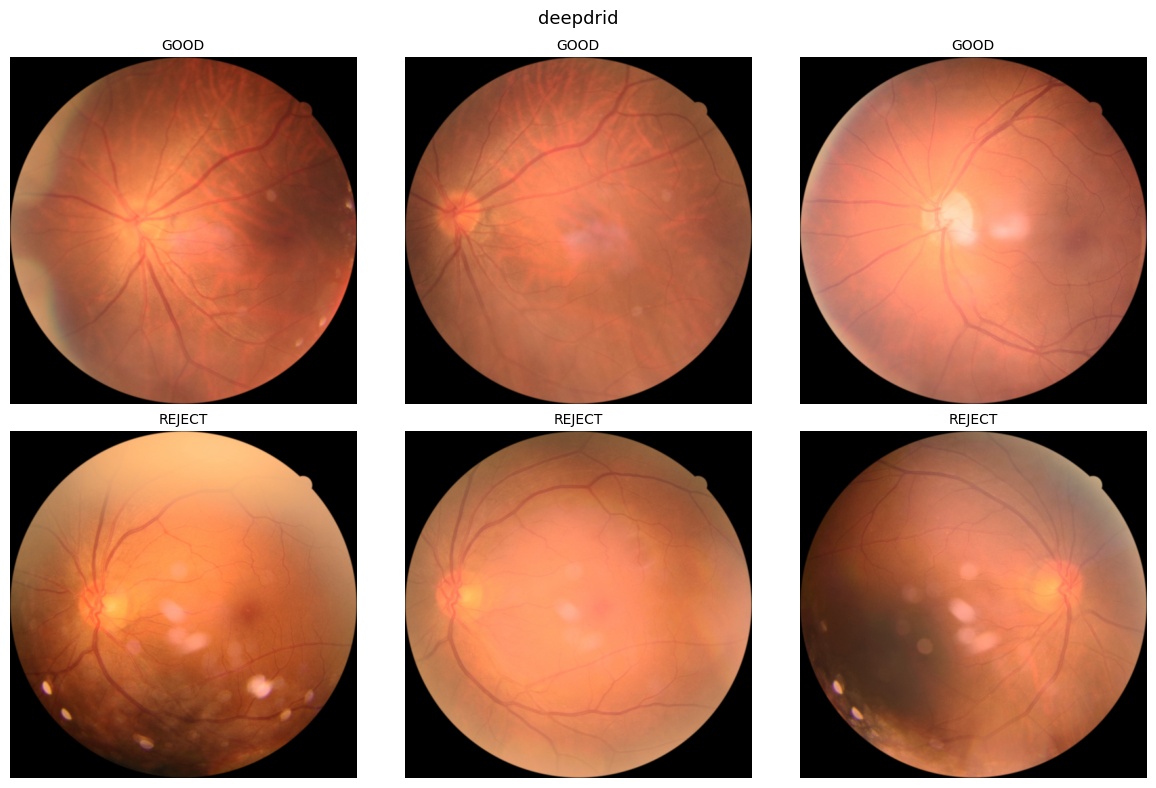

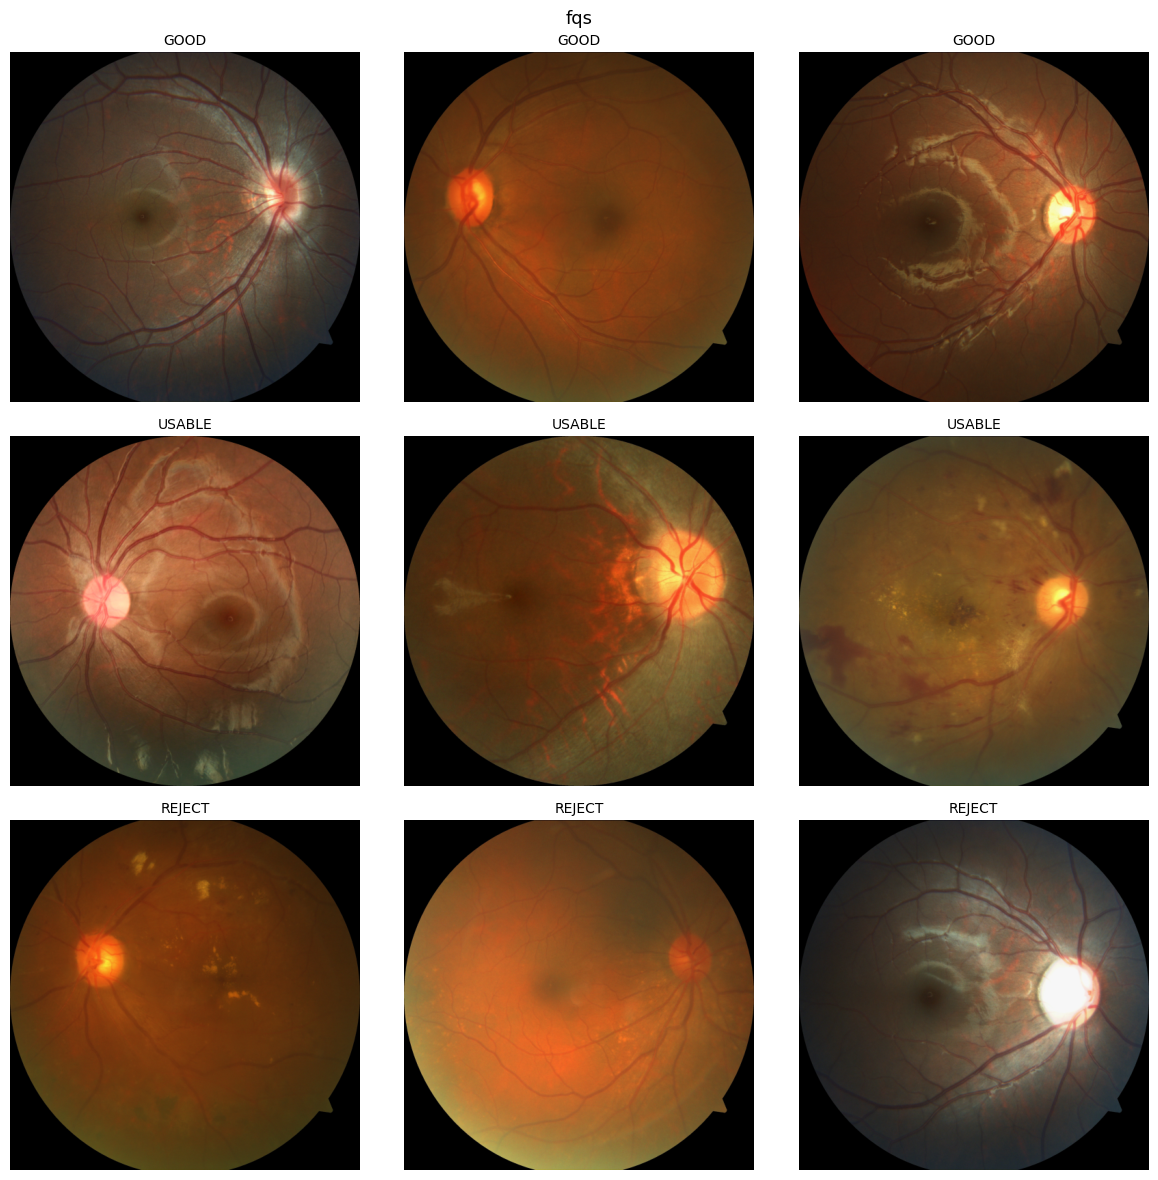

In [18]:
# --- 2: label direction, post-preprocessing ---
for ds in manifest[manifest.role == "external"].dataset.unique():
    sub = manifest[manifest.dataset == ds]
    classes = sorted(sub.quality.unique())
    fig, axes = plt.subplots(len(classes), 3,
                             figsize=(12, 4 * len(classes)))
    axes = np.atleast_2d(axes)
    for r, q in enumerate(classes):
        for ax in axes[r]:
            ax.axis("off")
        for ax, (_, row) in zip(axes[r], sub[sub.quality == q].head(3).iterrows()):
            img = cv2.imread(str(OUT / row.filename))
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            ax.set_title(["GOOD", "USABLE", "REJECT"][q], fontsize=10)
    plt.suptitle(ds, fontsize=13)
    plt.tight_layout()
    plt.show()

Top row should look clearly better than the bottom. FQS is the only one with three
rows — the middle should sit visibly between the other two.

DRIMDB will be strikingly obvious. DeepDRiD will be subtle, and that is expected: good
and bad are genuinely hard to separate there, which is why the best result in the
official ISBI 2020 challenge was 69.81% accuracy.

## 8 · Clean up and publish

In [19]:
for junk in ["sample", "scratch", "raw", ".virtual_documents"]:
    shutil.rmtree(WORK / junk, ignore_errors=True)

print(sorted(p.name for p in WORK.iterdir()))
print(f"{len(list(OUT.iterdir())):,} images")
!du -sh {OUT}
!df -h /kaggle/working

['__notebook__.ipynb', 'external_512', 'manifest_external_512.csv']
4,556 images
1.1G	/kaggle/working/external_512
Filesystem      Size  Used Avail Use% Mounted on
/dev/loop1       20G  1.2G   19G   6% /kaggle/working


1. **Save Version → Save & Run All (Commit)**
2. Output tab → **New Dataset** → `retina-external-512`, **Private**
3. Attach alongside `eyeq-512-preprocessed` in your modelling notebooks

### Then paste back to the repo

**File → Download** this notebook, commit to `notebooks/`. Copy the loaders into
`src/data/load.py`.

---

## For `docs/data-provenance.md`

```markdown
## DRIMDB
- Kaggle: subhajournal/drimdb-diabetic-retinopathy-images-database
- Verified: 216 at class-folder top level (Good 125 / Bad 69 / Outlier 22),
  matching Sevik et al. 194 used after dropping outliers.
- Nested <class>/drimdb_<class>/iwebalbumfiles/ are iWeb gallery exports
  (thumbnails + web derivatives) and are excluded by folder depth.
- Native 760x570 - ~5x lower than IDRiD. No patient identifiers.

## IDRiD
- Kaggle: mohamedabdalkader/indian-diabetic-retinopathy-image-dataset-idrid
- CC BY-SA 4.0; original IEEE DataPort release is CC BY 4.0.
- Upload merges two sources: 516 at 4288x2848 (IDRiD native, matches the
  published count) and 1032 at 4880x3862 (different aspect ratio, unknown
  provenance). Only the 516 native images are used.
- Train and Test each renumber from 0001, so ids are split-prefixed.
- Added clinical captions are not used. Role: pathology control only.

## DeepDRiD
- Kaggle: nancyhisham/deepdrid - mirror of github.com/deepdrdoc/DeepDRiD,
  confirmed by bundled LICENSE and README. Kaggle licence field: Unknown.
- Citation: Liu et al. (2022), Patterns 3(6):100512
- regular_fundus_images only; ultra-widefield excluded as a different
  imaging modality. regular-fundus-source-*.csv excluded - no quality column.
- Label direction verified against sub-scores: quality 1 has higher clarity
  (8.66 vs 7.11) and 3.2x fewer artifacts (1.27 vs 4.11), so 1 = good.

## FQS
- Source: figshare, FIQS_Dataset_Fundus_Image_Quality_Scores_ (9.07 GiB)
- Citation: Gong, Zheng, Zhuo Deng, Run Gan, et al. 2025. "Acquire Continuous
  and Precise Score for Fundus Image Quality Assessment: FTHNet and FQS
  Dataset." Scientific Reports 15: 40524.
- Uploaded to Kaggle privately as fqs-fundus-quality-scores. Only images/
  (1024x1024) and divisions/ were uploaded; full_size_images/ (1942x1942,
  7.4 GB) was omitted to reduce upload size.
- CAVEAT: double resize. Authors cropped 2656x1992 -> 1942x1942, then
  standardised to 1024x1024; we then resize to 512. Filter used in their
  1942 -> 1024 step is not documented. Applied uniformly to all images, so
  systematic rather than label-correlated.
- Images are already border-cropped and square, so crop_fov and pad_square
  are effectively no-ops. Same pipeline applied regardless.
- Labels from divisions/cross_validation-00-{train,val,test}.xlsx, which
  together cover all 2,246 images exactly once (1797 + 112 + 337). The other
  nine folds are alternative random splits of the same images.
- Thresholds (paper): Good 80-100, Usable 60-79, Reject 0-59 on MOS.
- EXIF stripped by the authors; no patient identifiers. patient_id falls
  back to image_id. LIMITATION.
- Class balance inverted relative to EyeQ (Good 23%, Usable 35%, Reject 42%)
  - deliberate, to cover more degradation types.
- SEMANTIC GAP, stated by the authors: in their own external validation on
  EyeQ they report a higher error rate in the Usable category, attributed to
  differences in quality assessment criteria between the datasets.
```

## For `docs/targets.md`

| Dataset | Expect | Why |
|---|---|---|
| **DRIMDB** | 95%+ | Visually obvious; published classifiers exceed 98%. Proves less than it looks. |
| **DeepDRiD** | **~70%** | Genuinely hard. Best in the official ISBI 2020 challenge was 69.81%. Near that is competitive. |
| **FQS** | lower than EyeQ | Inverted class prior (42% Reject) and a documented semantic gap on Usable. Report the confusion matrix, not just accuracy. |
| **IDRiD** | all Good | Control. Diseased retinas flagged ungradable = learned pathology, not quality. |

**Published cross-dataset benchmark, reverse direction.** Gong et al. trained FTHNet on
FQS and applied it to all 28,790 EyeQ images, reporting per-class recall **Good 0.96,
Usable 0.90, Reject 0.99** (their Fig. 5b). Worth citing in the discussion — their
Usable recall of 0.90 against your classical baseline's 0.450 suggests continuous-MOS
regression supervision buys real accuracy on the class you find hardest.